# Telco Customer Churn Prediction

## CM2604 - Machine Learning - Individual Coursework

---

**Name** : Nadija Ranawaka  
**IIT** : 20240696
**RGU** : 2522857

## 1. Introduction

Customer churn refers to a situation where a customer stops using a company's products or services. Predicting customer churn is an important task for telecommunications companies because identifying customers who are likely to leave can help the company take appropriate actions to improve customer retention.

In this project, machine learning classification techniques are used to predict whether a telecommunications customer will churn. The Telco Customer Churn dataset contains information about customers' demographic characteristics, services, contract information, tenure, and billing details.

The project consists of three main tasks. First, Exploratory Data Analysis (EDA) is performed to understand the characteristics and patterns within the dataset. Second, the data is preprocessed and three binary classification algorithms, K-Nearest Neighbours (KNN), Logistic Regression, and Random Forest, are implemented and optimized using hyperparameter tuning. Finally, the models are evaluated and compared using appropriate classification metrics.

The project also considers ethical issues associated with developing and deploying machine learning models for customer churn prediction.

## 2. Dataset Description

The dataset used in this project is the Telco Customer Churn dataset. It contains information about 7,043 telecommunications customers and 21 attributes. The attributes describe different aspects of the customers, including demographic information, subscribed services, account information, contract type, customer tenure, and charges.

The target variable is `Churn`, which indicates whether a customer has discontinued the telecommunications service.

The target variable contains two possible classes:

- `Yes` — the customer has churned.
- `No` — the customer has not churned.

Since the target variable contains two classes, this project is a **binary classification problem**.

## 3. Importing Libraries

The required Python libraries are imported for data manipulation, numerical operations, data visualization, and statistical analysis.

In [30]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

## 4. Loading the Dataset

The Telco Customer Churn dataset is loaded into a Pandas DataFrame. A DataFrame provides a tabular structure that allows the dataset to be efficiently inspected, cleaned, visualized, and analyzed.

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

## 5. Initial Dataset Inspection

An initial inspection of the dataset is performed to verify that the data has been loaded correctly and to understand its basic structure. The first few records are displayed to observe the types of information contained in the dataset.

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 5.1 Dataset Dimensions

The dimensions of the dataset are examined to determine the number of customer records and attributes available for analysis.

In [4]:
df.shape

(7043, 21)

The dataset contains 7,043 customer records and 21 attributes. Each row represents an individual telecommunications customer, while each column represents a customer attribute such as demographic information, subscribed services, contract details, tenure, and billing information. The `Churn` attribute will be used as the target variable for the binary classification task.

### 5.2 Dataset Information

The `info()` method is used to examine the data types and number of non-null observations for each variable. This provides an initial understanding of the numerical and categorical variables and helps identify potential missing values.

In [5]:
dataset_info = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notnull().sum().values,
    "Missing Values": df.isnull().sum().values
})

dataset_info.style.hide(axis="index")

Column,Data Type,Non-Null Count,Missing Values
customerID,str,7043,0
gender,str,7043,0
SeniorCitizen,int64,7043,0
Partner,str,7043,0
Dependents,str,7043,0
tenure,int64,7043,0
PhoneService,str,7043,0
MultipleLines,str,7043,0
InternetService,str,7043,0
OnlineSecurity,str,7043,0


### 5.3 Statistical Summary

Descriptive statistics are examined for the numerical variables in the dataset. This provides information such as the mean, standard deviation, minimum, maximum, and quartile values. These statistics help identify the general distribution and range of the numerical attributes.

In [6]:
statistical_summary = df.describe().T

statistical_summary = statistical_summary[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]

statistical_summary

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


The statistical summary provides an overview of the numerical attributes in the dataset. It shows the number of available observations (`count`), average value (`mean`), variation in the data (`std`), minimum and maximum values, and the 25th, 50th, and 75th percentiles. This gives an initial understanding of the range and distribution of the numerical attributes before performing more detailed exploratory data analysis.

### 5.4 Dataset Attributes

The names of all variables are examined to understand the attributes available in the dataset and to identify the target variable used for classification.

In [7]:
attribute_description = pd.DataFrame({
    "Attribute": [
        "customerID",
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents",
        "tenure",
        "PhoneService",
        "MultipleLines",
        "InternetService",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies",
        "Contract",
        "PaperlessBilling",
        "PaymentMethod",
        "MonthlyCharges",
        "TotalCharges",
        "Churn"
    ],
    "Description": [
        "Unique identifier assigned to each customer.",
        "Customer's gender.",
        "Indicates whether the customer is a senior citizen.",
        "Indicates whether the customer has a partner.",
        "Indicates whether the customer has dependents.",
        "Number of months the customer has been with the company.",
        "Indicates whether the customer has a phone service.",
        "Indicates whether the customer has multiple phone lines.",
        "Type of internet service used by the customer.",
        "Indicates whether the customer has online security.",
        "Indicates whether the customer has online backup.",
        "Indicates whether the customer has device protection.",
        "Indicates whether the customer has technical support.",
        "Indicates whether the customer has a streaming TV service.",
        "Indicates whether the customer has a streaming movie service.",
        "Type of contract held by the customer.",
        "Indicates whether the customer uses paperless billing.",
        "Payment method used by the customer.",
        "Monthly amount charged to the customer.",
        "Total amount charged to the customer.",
        "Indicates whether the customer has left the company."
    ]
})

attribute_description.style.hide(axis="index")

Attribute,Description
customerID,Unique identifier assigned to each customer.
gender,Customer's gender.
SeniorCitizen,Indicates whether the customer is a senior citizen.
Partner,Indicates whether the customer has a partner.
Dependents,Indicates whether the customer has dependents.
tenure,Number of months the customer has been with the company.
PhoneService,Indicates whether the customer has a phone service.
MultipleLines,Indicates whether the customer has multiple phone lines.
InternetService,Type of internet service used by the customer.
OnlineSecurity,Indicates whether the customer has online security.


### 5.5 Missing Values

Missing values can affect the performance and reliability of machine learning models. Therefore, the number of missing values in each attribute is examined before proceeding with further analysis.

In [8]:
missing_values = pd.DataFrame({
    "Attribute": df.columns,
    "Missing Values": df.isnull().sum().values
})

missing_values.style.hide(axis="index")

Attribute,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


The dataset does not contain any explicit missing (`NaN`) values. However, the `TotalCharges` attribute contains blank string values that are not detected as standard missing values. These will be handled during the data preprocessing stage.

### 5.6 Duplicate Records

Duplicate records can introduce bias into the analysis and may cause certain observations to be given more importance than intended. Therefore, the dataset is checked for duplicate rows.

In [9]:
duplicate_count = df.duplicated().sum()

duplicate_summary = pd.DataFrame({
    "Measure": ["Duplicate Records"],
    "Count": [duplicate_count]
})

duplicate_summary.style.hide(axis="index")

Measure,Count
Duplicate Records,0


The dataset contains no duplicate records. Therefore, no duplicate customer records need to be removed at this stage."

## 6. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to identify patterns, distributions, relationships, and potential issues within the dataset. Understanding these characteristics is important before developing the classification models.

### 6.1 Churn Distribution

The distribution of the target variable, `Churn`, is examined to determine the proportion of customers who churned and those who remained with the service. This is important for understanding the class distribution of the classification problem.

In [10]:
churn_counts = df["Churn"].value_counts()

churn_counts

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
churn_percentages = df["Churn"].value_counts(normalize=True) * 100

churn_percentages

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

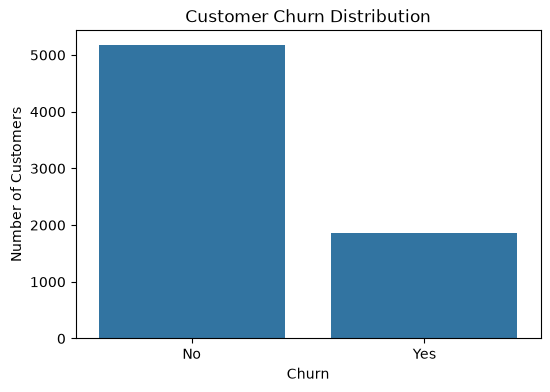

In [12]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

The target variable is imbalanced, with 73.46% of customers not churning and 26.54% churning. This indicates that the dataset contains substantially more customers who remained with the company than customers who left. Therefore, accuracy alone may not be sufficient for evaluating the classification models, and metrics such as precision, recall, and F1-score should also be considered.

### 6.2 Tenure Distribution by Churn

The relationship between customer tenure and churn is examined to determine whether customers who leave the company tend to have shorter or longer periods of service. This may help identify whether customer loyalty or length of time with the company is associated with churn.

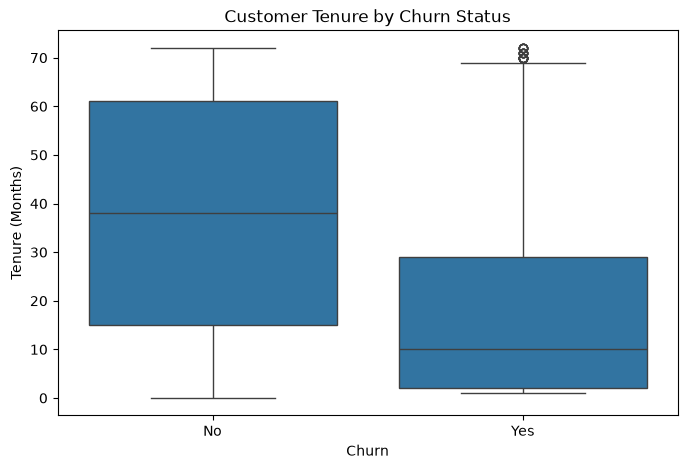

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

The boxplot shows a clear difference in customer tenure between the two churn groups. Customers who did not churn generally have longer tenures, while customers who churned tend to have shorter tenures. This suggests that customers who have been with the company for a shorter period may be more likely to churn. A small number of high-tenure customers are also observed as outliers within the churned group.

### 6.3 Monthly Charges by Churn

The relationship between monthly charges and customer churn is examined to determine whether customers who leave the company tend to have higher or lower monthly charges compared with customers who remain.

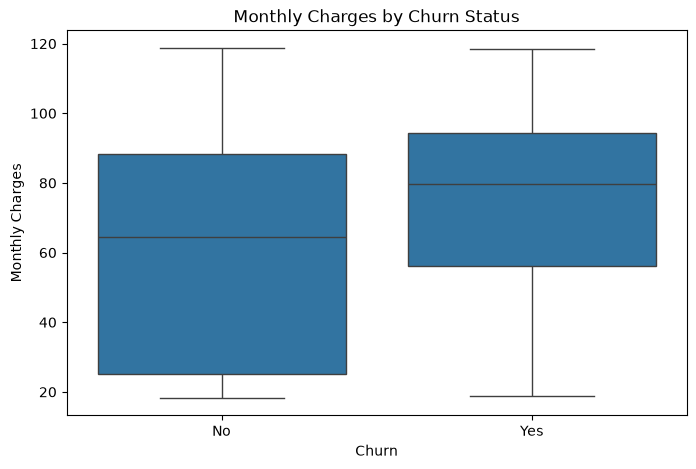

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

The boxplot shows that customers who churned generally have higher monthly charges than customers who remained with the company. The central range for churned customers is concentrated at higher charge values, suggesting that customers with higher monthly charges may be more likely to churn. However, this relationship represents an observed association and does not imply that higher charges directly cause customers to leave.

### 6.4 Contract Type and Churn

The relationship between contract type and customer churn is examined to determine whether customers with different contract durations have different levels of churn. Churn rates are compared across month-to-month, one-year, and two-year contracts.

In [15]:
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn_rate

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


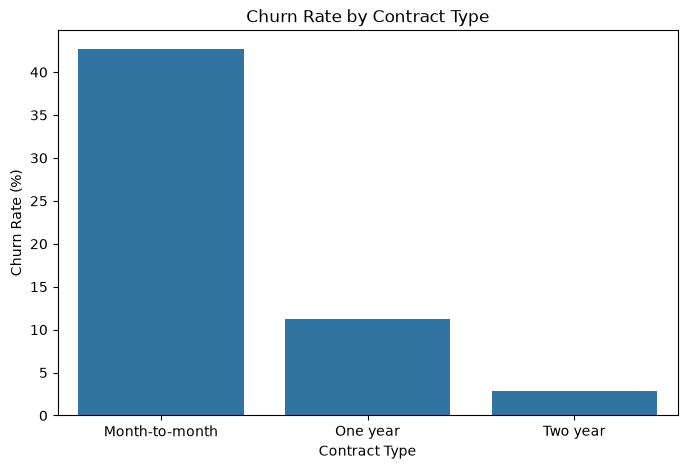

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn_rate.index,
    y=contract_churn_rate["Yes"]
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

The analysis shows a strong relationship between contract type and customer churn. Customers with month-to-month contracts have the highest churn rate at 42.71%, compared with 11.27% for one-year contracts and only 2.83% for two-year contracts. This suggests that customers on shorter-term contracts are more likely to churn than customers on longer-term contracts. However, this observed relationship does not establish that contract type directly causes customers to churn.

### 6.5 Internet Service and Churn

The relationship between internet service type and customer churn is examined to determine whether customers using different types of internet services have different churn rates.

In [17]:
internet_churn_rate = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn_rate

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


The analysis shows a clear difference in churn rates across internet service types. Customers using fiber optic internet have the highest churn rate at 41.89%, compared with 18.96% for DSL customers and 7.40% for customers without internet service. This suggests that internet service type may be associated with customer churn. However, this relationship does not establish that the type of internet service directly causes customers to churn.

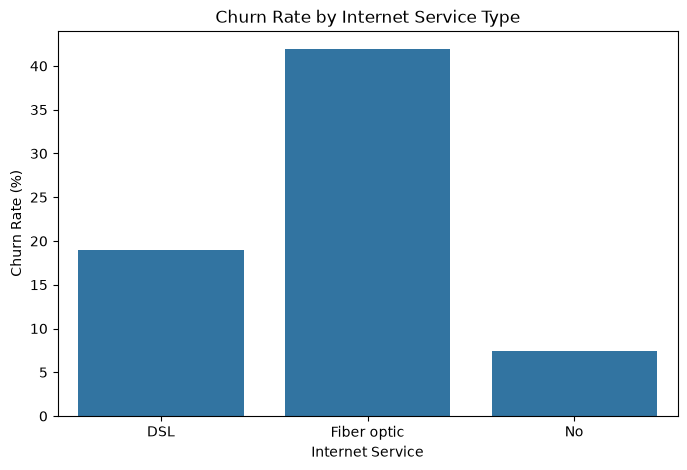

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn_rate.index,
    y=internet_churn_rate["Yes"]
)

plt.title("Churn Rate by Internet Service Type")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.show()

### 6.6 Payment Method and Churn

The relationship between payment method and customer churn is examined to determine whether customers using different payment methods have different churn rates.

In [19]:
payment_churn_rate = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn_rate

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


The analysis shows a noticeable difference in churn rates across payment methods. Customers who use electronic checks have the highest churn rate at 45.29%, while customers using automatic credit card payments have the lowest churn rate at 15.24%. The churn rates for automatic bank transfers and mailed checks are 16.71% and 19.11%, respectively. This suggests that payment method may be associated with customer churn, although the observed relationship does not establish that payment method directly causes customers to churn.

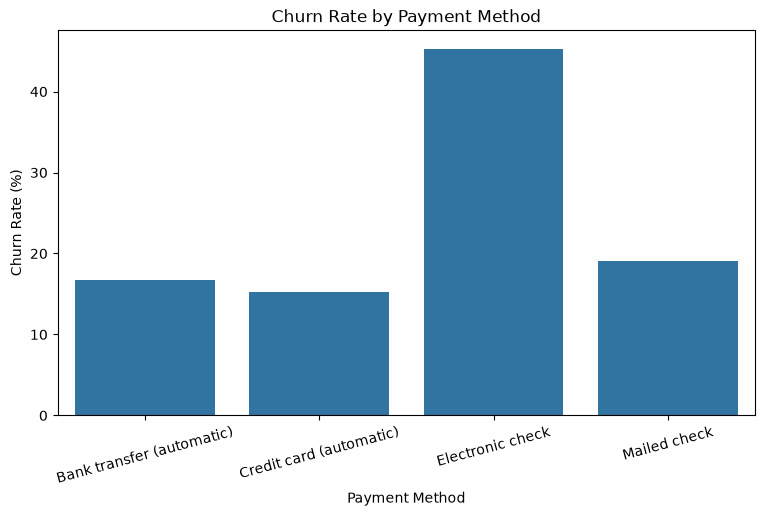

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=payment_churn_rate.index,
    y=payment_churn_rate["Yes"]
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.show()

## 7. Data Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning. The preprocessing steps include handling missing or invalid values, removing irrelevant attributes, encoding categorical variables, separating the target variable, and preparing the features for the classification models.

### 7.1 Handling Missing Values in `TotalCharges`

The `TotalCharges` attribute should contain numerical values representing the total amount charged to each customer. However, some records contain blank values instead of numerical values. These blank entries must be identified and handled before the machine learning models are trained.

In [21]:
df["TotalCharges"].isna().sum(), (df["TotalCharges"] == " ").sum()
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])
df["TotalCharges"].isna().sum()

np.int64(11)

### 7.2 Handling Missing `TotalCharges` Values

After converting the blank values in `TotalCharges` to missing values, 11 records were identified. These records represent a very small proportion of the dataset. Since `TotalCharges` is an important numerical feature and the number of affected records is negligible compared with the overall dataset size, these records are removed from the analysis rather than imputing potentially inaccurate values.

In [22]:
df = df.dropna(subset=["TotalCharges"])
df["TotalCharges"].isna().sum()

np.int64(0)

The 11 records containing missing `TotalCharges` values have been removed. The dataset now contains 7,032 customer records with no missing values in `TotalCharges`.

### 7.3 Removing the `customerID` Attribute

The `customerID` attribute is removed because it is a unique identifier assigned to each customer and does not provide meaningful information about customer behaviour or churn. Including this identifier as a model feature would not help the model generalize to unseen customers.

In [23]:
df = df.drop(columns=["customerID"])
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

### 7.4 Separating Features and Target

The dataset is divided into input features and the target variable. The input features contain the customer information used by the machine learning models, while `Churn` is the target variable that the models will predict.

In [24]:
X = df.drop(columns=["Churn"])
y = df["Churn"]
X.shape, y.shape

((7032, 19), (7032,))

### 7.5 Encoding the Target Variable

The `Churn` target variable contains categorical values, `Yes` and `No`. These values are converted into numerical labels so that they can be used by the machine learning models. `No` is represented as 0 and `Yes` is represented as 1.

In [25]:
y = y.map({"No": 0, "Yes": 1})
y.value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

### 7.6 Identifying Numerical and Categorical Features

The input features are divided into numerical and categorical variables because they require different preprocessing techniques. Numerical features can be scaled, while categorical features need to be converted into numerical representations through encoding.

In [26]:
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["str"]).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 7.7 Train-Test Split

The dataset is divided into training and testing sets. The training set is used to develop the machine learning models, while the testing set is reserved for evaluating their performance on unseen data.

An 80:20 split is used, with 80% of the data allocated for training and 20% for testing. Stratified sampling is applied to maintain a similar proportion of churned and non-churned customers in both sets.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5625, 19), (1407, 19), (5625,), (1407,))

### 7.8 Encoding Categorical Features and Scaling Numerical Features

The categorical features are converted into numerical representations using one-hot encoding so that they can be used by the machine learning algorithms. Numerical features are standardized so that they have a comparable scale, which is particularly important for distance-based algorithms such as KNN.

A `ColumnTransformer` is used to apply the appropriate preprocessing to each group of features.

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

## 8. Model Training and Hyperparameter Tuning

Three classification algorithms are evaluated: K-Nearest Neighbours (KNN), Logistic Regression, and Random Forest. A preprocessing pipeline is used to apply the required transformations before each model is trained. Hyperparameter tuning is then performed to identify suitable model configurations.

### 8.1 K-Nearest Neighbours (KNN)

KNN is a supervised classification algorithm that predicts the class of a new observation by examining the classes of its nearest neighbours. Since KNN relies on distances between observations, numerical feature scaling is particularly important.

In [31]:
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier())
])

In [32]:
knn_param_grid = {
    "model__n_neighbors": [5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': [5, 7, ...], 'model__p': [1, 2], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0

In [33]:
print("Best parameters:", knn_search.best_params_)
print("Best cross-validation F1-score:", knn_search.best_score_)

Best parameters: {'model__n_neighbors': 15, 'model__p': 2, 'model__weights': 'uniform'}
Best cross-validation F1-score: 0.5820330180133314


### 8.2 KNN Evaluation

The best KNN configuration was selected using five-fold cross-validation based on F1-score. The selected model is evaluated on the held-out test set using accuracy, precision, recall, F1-score, and ROC-AUC.

In [34]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

knn_best = knn_search.best_estimator_

y_pred_knn = knn_best.predict(X_test)
y_prob_knn = knn_best.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_knn, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_knn, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))

Accuracy: 0.7732764747690121
Precision: 0.5741239892183289
Recall: 0.56951871657754
F1-score: 0.5718120805369128
ROC-AUC: 0.8155520238545123

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.85      0.85      1033
           1       0.57      0.57      0.57       374

    accuracy                           0.77      1407
   macro avg       0.71      0.71      0.71      1407
weighted avg       0.77      0.77      0.77      1407



### 8.3 Logistic Regression

Logistic Regression estimates the probability that a customer belongs to a class. In this project, it predicts whether a customer will churn. Hyperparameter tuning is performed using five-fold cross-validation and F1-score to identify a suitable model configuration.

In [35]:
logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

logreg_param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

logreg_search = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=logreg_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

logreg_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of

In [36]:
print("Best parameters:", logreg_search.best_params_)
print("Best cross-validation F1-score:", logreg_search.best_score_)

Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Best cross-validation F1-score: 0.6333403588243568


### 8.4 Logistic Regression Evaluation

The best Logistic Regression configuration was selected using five-fold cross-validation based on F1-score. The selected model is evaluated on the held-out test set using accuracy, precision, recall, F1-score, and ROC-AUC to assess its classification performance.

In [37]:
logreg_best = logreg_search.best_estimator_

y_pred_logreg = logreg_best.predict(X_test)
y_prob_logreg = logreg_best.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_logreg))
print("Precision:", precision_score(y_test, y_pred_logreg, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_logreg, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_logreg, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_logreg))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logreg, zero_division=0))

Accuracy: 0.7256574271499645
Precision: 0.4901315789473684
Recall: 0.7967914438502673
F1-score: 0.6069246435845214
ROC-AUC: 0.8351344145860403

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



### 8.5 Random Forest

Random Forest is an ensemble classification algorithm that combines predictions from multiple decision trees. Combining trees can capture complex relationships in the data and help reduce overfitting compared with relying on a single tree. Hyperparameter tuning is performed using five-fold cross-validation and F1-score.

In [38]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    "model__n_estimators": [100],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__class_weight": [None, "balanced"]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [None, 10, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callabl

In [39]:
print("Best parameters:", rf_search.best_params_)
print("Best cross-validation F1-score:", rf_search.best_score_)

Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best cross-validation F1-score: 0.6318452311141866


### 8.6 Random Forest Evaluation

The best Random Forest configuration was selected using five-fold cross-validation based on F1-score. Its performance is evaluated on the held-out test set using accuracy, precision, recall, F1-score, and ROC-AUC.

In [41]:
rf_best = rf_search.best_estimator_

y_pred_rf = rf_best.predict(X_test)
y_prob_rf = rf_best.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_rf, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Accuracy: 0.746268656716418
Precision: 0.5151515151515151
Recall: 0.7727272727272727
F1-score: 0.6181818181818182
ROC-AUC: 0.8303640297974333

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1033
           1       0.52      0.77      0.62       374

    accuracy                           0.75      1407
   macro avg       0.71      0.75      0.71      1407
weighted avg       0.80      0.75      0.76      1407



### 8.7 Model Comparison

The three classification models are compared using accuracy, precision, recall, F1-score, and ROC-AUC on the held-out test set. F1-score is used as the primary comparison metric because it balances precision and recall, while ROC-AUC measures the models' ability to distinguish between customers who churn and those who remain.

In [42]:
results = pd.DataFrame([
    {
        "Model": "KNN",
        "CV F1-score": knn_search.best_score_,
        "Accuracy": accuracy_score(y_test, y_pred_knn),
        "Precision": precision_score(y_test, y_pred_knn, zero_division=0),
        "Recall": recall_score(y_test, y_pred_knn, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_knn, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_knn)
    },
    {
        "Model": "Logistic Regression",
        "CV F1-score": logreg_search.best_score_,
        "Accuracy": accuracy_score(y_test, y_pred_logreg),
        "Precision": precision_score(y_test, y_pred_logreg, zero_division=0),
        "Recall": recall_score(y_test, y_pred_logreg, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_logreg, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_logreg)
    },
    {
        "Model": "Random Forest",
        "CV F1-score": rf_search.best_score_,
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(y_test, y_pred_rf, zero_division=0),
        "Recall": recall_score(y_test, y_pred_rf, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_rf, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
    }
])

results = results.sort_values("F1-score", ascending=False)
results.round(3)

,Model,CV F1-score,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Random Forest,0.632,0.746,0.515,0.773,0.618,0.830
1,Logistic Regression,0.633,0.726,0.490,0.797,0.607,0.835
0,KNN,0.582,0.773,0.574,0.570,0.572,0.816


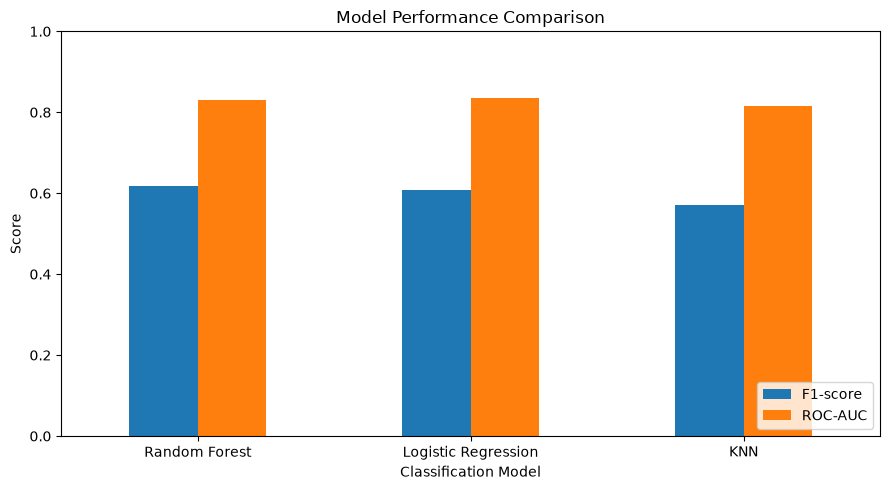

In [43]:
import matplotlib.pyplot as plt

results.plot(
    x="Model",
    y=["F1-score", "ROC-AUC"],
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation**

Random Forest achieved the highest test F1-score (0.618), followed by Logistic Regression (0.607) and KNN (0.572). This indicates that Random Forest provided the best balance between precision and recall at the default classification threshold.

Logistic Regression achieved the highest recall (0.797) and ROC-AUC (0.835), indicating that it identified a greater proportion of customers who churned and showed the strongest overall ability to distinguish between the two classes. Random Forest also achieved strong recall (0.773).

KNN performed less effectively than the other models on F1-score and ROC-AUC. Overall, Random Forest is the preferred model when prioritising F1-score, whereas Logistic Regression may be preferable when identifying as many customers at risk of churn as possible is the main objective. The final choice depends on the relative costs of missed churners and false alarms.

### 8.8 Experimental Settings and Best Hyperparameters

Hyperparameter tuning was conducted using GridSearchCV with five-fold cross-validation. The F1-score was used as the selection metric to balance precision and recall when identifying customers who churn. All preprocessing steps were included within the model pipelines to prevent information leakage from the validation folds.

The best hyperparameter configurations selected for each classifier are summarized below.

In [44]:
best_settings = pd.DataFrame([
    {
        "Model": "KNN",
        "Best Hyperparameters": str(knn_search.best_params_),
        "Best CV F1-score": knn_search.best_score_
    },
    {
        "Model": "Logistic Regression",
        "Best Hyperparameters": str(logreg_search.best_params_),
        "Best CV F1-score": logreg_search.best_score_
    },
    {
        "Model": "Random Forest",
        "Best Hyperparameters": str(rf_search.best_params_),
        "Best CV F1-score": rf_search.best_score_
    }
])

best_settings.round(3)

,Model,Best Hyperparameters,Best CV F1-score
0,KNN,"{'model__n_neighbors': 15, 'model__p': 2, 'mod...",0.582
1,Logistic Regression,"{'model__C': 1, 'model__class_weight': 'balanc...",0.633
2,Random Forest,"{'model__class_weight': 'balanced', 'model__ma...",0.632
